# Analysis behind the slides
**Bolt Send × eWAKA · Santa Clara University MSBA · Analytics Showdown, Fall 2026**
**Team:** Sinhye Kim, Yan Wu, Wei-Chia Lin, Ethan Casey

Each section reproduces the numbers on one or more slides; the slide number is in every heading.
Prediction models A and B (slides 17–18) are in `BoltSend_eWAKA_prediction_models.ipynb`; Model C (slides 12 and 19) is `demand_forecast.py`. A short version for live use during the talk is `BoltSend_eWAKA_presentation_demo.ipynb`.

**Data:** keep `boltsend_rider_history.xlsx` and `boltsend_rider_perfomance.xlsx` (original names, including the "perfomance" spelling) in the same folder as this notebook.

**Main comparison:** bicycles May–Aug 2025 vs motorbikes May–Aug 2026, optional rides excluded, unless a section says otherwise.

## Setup: load and prepare the data

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

TEAL, ORANGE, RED, GREEN, GRAY = '#1B7A83', '#D4690F', '#B5392F', '#1F7A4D', '#6B7B74'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})

hist = pd.read_excel('boltsend_rider_history.xlsx')
perf = pd.read_excel('boltsend_rider_perfomance.xlsx')

hist['dt'] = pd.to_datetime(hist['date'].str[:19])            # order time (local)
hist['day'] = hist['dt'].dt.normalize()
hist['moto'] = hist['vehicle_model'].isin(['eWAKA Jasiri', 'RhingGo M300'])
perf['day'] = pd.to_datetime(perf['report_date'])

orders = hist[hist['optional_ride'].isna()].sort_values(['individual_identifier', 'dt']).copy()   # non-optional offers
bike = orders[~orders['moto'] & (orders['dt'] >= '2025-05-01') & (orders['dt'] < '2025-09-01')].copy()
moto = orders[orders['moto'] & (orders['dt'] >= '2026-05-01') & (orders['dt'] < '2026-09-01')].copy()
N_DAYS = 123                                                    # May 1 - Aug 31

NR, FIN, REJ = 'Driver did not respond', 'Finished', 'Driver rejected'
CUST = ['Rider cancelled', 'Rider did not show']                # 'Rider' = customer in this data

print(f"All events: {len(hist):,} | non-optional: {len(orders):,}")
print(f"Bicycle May-Aug 2025: {len(bike):,} orders, {bike['individual_identifier'].nunique()} couriers")
print(f"Motorbike May-Aug 2026: {len(moto):,} orders, {moto['individual_identifier'].nunique()} couriers")

All events: 110,578 | non-optional: 104,396
Bicycle May-Aug 2025: 45,947 orders, 213 couriers
Motorbike May-Aug 2026: 9,086 orders, 21 couriers


## Slides 2, 3 and 13: headline numbers and context

In [2]:
print(f"No-response: bicycle 2025 {(bike['status']==NR).mean():.1%} -> motorbike 2026 {(moto['status']==NR).mean():.1%}")
all_cx = hist[hist['status'].isin(CUST)]
moto_cx = moto[moto['status'].isin(CUST)]
print(f"Customer cancellations + no-shows, all data: {len(all_cx):,}; with a cancellation fee > 0: {(all_cx['cancellation_feesksh'] > 0).sum()}")
print(f"Customer cancellations + no-shows, motorbike May-Aug 2026: {len(moto_cx):,}")
print(f"Cash share of motorbike orders: {(moto['payment_type']=='Cash').mean():.1%}")

No-response: bicycle 2025 6.9% -> motorbike 2026 14.0%
Customer cancellations + no-shows, all data: 28,526; with a cancellation fee > 0: 0
Customer cancellations + no-shows, motorbike May-Aug 2026: 2,311
Cash share of motorbike orders: 96.1%


## Slide 4: where we started (resampling comparison)
All 21 motorbike couriers vs 21 bicycle couriers drawn at random from 213, repeated 500 times. "Per day" = all 21 couriers combined, divided by 123 calendar days.

In [3]:
def group_metrics(df, couriers, start, end):
    x = df[df['individual_identifier'].isin(couriers)]
    p = perf[perf['individual_identifier'].isin(couriers) & (perf['day'] >= start) & (perf['day'] < end)]
    fin = (x['status'] == FIN).sum()
    return [len(x) / N_DAYS, fin / N_DAYS, fin / (p['online_time_min'].sum() / 60), fin / len(x) * 100]

cols = ['Orders per day', 'Completed per day', 'Completed per online hour', 'Completion rate (%)']
moto_ids, bike_ids = np.sort(moto['individual_identifier'].unique()), np.sort(bike['individual_identifier'].unique())
moto_row = group_metrics(moto, moto_ids, '2026-05-01', '2026-09-01')

rng = np.random.default_rng(0)
draws = np.array([group_metrics(bike, rng.choice(bike_ids, len(moto_ids), replace=False), '2025-05-01', '2025-09-01') for _ in range(500)])
slide4 = pd.DataFrame([draws.mean(0), np.percentile(draws, 2.5, 0), np.percentile(draws, 97.5, 0), moto_row],
                      index=['Bicycle 2025: mean of 500 draws', 'Bicycle: 2.5th percentile', 'Bicycle: 97.5th percentile', 'Motorbike 2026 (all 21)'],
                      columns=cols)
slide4.round(2)

,Orders per day,Completed per day,Completed per online hour,Completion rate (%)
Bicycle 2025: mean of 500 draws,36.78,21.92,0.73,59.56
Bicycle: 2.5th percentile,23.85,13.65,0.63,53.17
Bicycle: 97.5th percentile,52.99,32.42,0.82,65.35
Motorbike 2026 (all 21),73.87,41.38,1.50,56.02


## Slide 5: completion is lost before couriers accept

In [4]:
def outcome_mix(df):
    s = df['status'].replace({'Rider did not show': 'Rider cancelled'}).value_counts(normalize=True) * 100
    return s.rename({'Rider cancelled': 'Customer cancelled or no-show', 'Driver cancelled': 'Courier cancelled', REJ: 'Courier rejected', NR: 'No response'})

mix = pd.DataFrame({'Bicycle 2025': outcome_mix(bike), 'Motorbike 2026': outcome_mix(moto)})
mix['Change (pts)'] = mix['Motorbike 2026'] - mix['Bicycle 2025']
display_mix = mix.round(1)

def accepted(df): return df[~df['status'].isin([NR, REJ])]
for name, df in [('Bicycle 2025', bike), ('Motorbike 2026', moto)]:
    a = accepted(df)
    print(f"{name}: completion after acceptance {(a['status']==FIN).mean():.1%} | "
          f"customer cancel/no-show among accepted {a['status'].isin(CUST).mean():.1%} | "
          f"median pickup (finished) {df.loc[df['status']==FIN, 'pickup_duration_min'].median():.1f} min")

accept_rate_2025 = 1 - bike['status'].isin([NR, REJ]).mean()
counterfactual = accept_rate_2025 * (accepted(moto)['status'] == FIN).mean()
print(f"Motorbike completion if no-response + rejection stayed at 2025 levels: {counterfactual:.1%}")
display_mix

Bicycle 2025: completion after acceptance 64.3% | customer cancel/no-show among accepted 30.3% | median pickup (finished) 10.2 min
Motorbike 2026: completion after acceptance 66.8% | customer cancel/no-show among accepted 30.3% | median pickup (finished) 4.3 min
Motorbike completion if no-response + rejection stayed at 2025 levels: 61.6%


,Bicycle 2025,Motorbike 2026,Change (pts)
status,,,
Finished,59.2,56.0,-3.2
Customer cancelled or no-show,27.9,25.4,-2.5
No response,6.9,14.0,7.1
Courier cancelled,4.9,2.4,-2.5
Courier rejected,0.9,2.1,1.2


## Slide 5 (speaker notes): slower pickups, more customer cancellations
Same method as Ethan's allocation notebook: all non-optional offers, January 2025 – August 2026, couriers with 10+ offers.
Pickup time is recorded only for finished orders, so each courier's typical speed is the median pickup on finished orders.

In [5]:
cp = orders.assign(cust=orders['status'].isin(CUST)).groupby('individual_identifier').agg(offers=('status', 'size'), cust_cancels=('cust', 'sum'), moto=('moto', 'max'))
cp['median_pickup'] = orders[orders['status'] == FIN].groupby('individual_identifier')['pickup_duration_min'].median()
cp = cp[(cp['offers'] >= 10) & cp['median_pickup'].notna()]
cp['speed_quartile'] = pd.qcut(cp['median_pickup'], 4, labels=['Q1 fastest', 'Q2', 'Q3', 'Q4 slowest'])
q = cp.groupby('speed_quartile', observed=True).agg(couriers=('offers', 'size'), offers=('offers', 'sum'), cust_cancels=('cust_cancels', 'sum'), median_pickup_min=('median_pickup', 'median'))
q['customer_cancel_pct'] = (q['cust_cancels'] / q['offers'] * 100).round(1)
rate = cp['cust_cancels'] / cp['offers']
print(f"Spearman, courier median pickup vs customer cancellation rate: {spearmanr(cp['median_pickup'], rate)[0]:.2f} ({len(cp)} couriers)")
for v, name in [(False, 'bicycle'), (True, 'motorbike')]:
    m = cp['moto'] == v
    print(f"  {name}: {spearmanr(cp.loc[m, 'median_pickup'], rate[m])[0]:.2f} ({m.sum()} couriers)")
q[['couriers', 'median_pickup_min', 'customer_cancel_pct']]

Spearman, courier median pickup vs customer cancellation rate: 0.41 (263 couriers)
  bicycle: 0.42 (240 couriers)
  motorbike: 0.43 (23 couriers)


,couriers,median_pickup_min,customer_cancel_pct
speed_quartile,,,
Q1 fastest,66,7.3750,23.3
Q2,66,9.6850,27.1
Q3,66,11.5025,28.7
Q4 slowest,65,14.8250,33.7


## Appendix A1 (slide 23): is it the vehicle? Missed offers by month, both vehicles

In [6]:
o2 = orders.assign(month=orders['dt'].dt.to_period('M'))
trend = o2.groupby(['month', 'moto']).agg(offers=('status', 'size'), couriers=('individual_identifier', 'nunique'),
                                          missed_pct=('status', lambda s: round((s == NR).mean() * 100, 1))).reset_index()
trend['vehicle'] = np.where(trend['moto'], 'Motorbike', 'Bicycle')
trend = trend[trend['offers'] >= 50].drop(columns='moto')   # drop months with almost no offers
print(trend.to_string(index=False))
light = moto.assign(hr=moto['dt'].dt.floor('h')).groupby(['individual_identifier', 'hr'])['status'].transform('size')
print(f"Motorbike misses when a courier gets 1 order that hour: {(moto.loc[light == 1, 'status'] == NR).mean():.1%}")

  month  offers  couriers  missed_pct   vehicle
2025-01    1668        26         1.9   Bicycle
2025-02    3892        37         2.6   Bicycle
2025-03    6483        63         5.0   Bicycle
2025-04    8963        98         6.5   Bicycle
2025-05    9839       116         4.2   Bicycle
2025-06    9753       123         6.1   Bicycle
2025-07   11598       124         7.1   Bicycle
2025-08   14757       124         9.2   Bicycle
2025-09   11410       104         9.7   Bicycle
2025-10    4070        67        12.6   Bicycle
2025-11    2275        37        17.1   Bicycle
2025-12    3713        29        29.8   Bicycle
2026-01    2176        23        22.2   Bicycle
2026-01      72         2         9.7 Motorbike
2026-02    2843        24        28.6   Bicycle
2026-02     118         1        11.0 Motorbike
2026-03    1190        20        28.3   Bicycle
2026-03      55         1        20.0 Motorbike
2026-04     396         5        14.6 Motorbike
2026-05    2396         9        13.8 Mo

## Slide 6: too many orders at once (order load per courier-hour)

In [7]:
LABELS = {1: '1 order', 2: '2 orders', 3: '3 orders', 4: '4 or more'}
def load_table(df):
    df = df.copy()
    df['load'] = df.groupby(['individual_identifier', df['dt'].dt.floor('h')])['status'].transform('size').clip(upper=4)
    t = df.groupby('load').agg(orders=('status', 'size'),
                               completion_rate=('status', lambda s: (s == FIN).mean() * 100),
                               no_response_rate=('status', lambda s: (s == NR).mean() * 100))
    t['share_of_orders'] = t['orders'] / t['orders'].sum() * 100
    return t.rename(index=LABELS)

def orders_per_online_hour(df, start, end):
    p = perf[perf['individual_identifier'].isin(df['individual_identifier'].unique()) & (perf['day'] >= start) & (perf['day'] < end)]
    return len(df) / (p['online_time_min'].sum() / 60)

print(f"Orders per online hour: bicycle {orders_per_online_hour(bike, '2025-05-01', '2025-09-01'):.2f} -> motorbike {orders_per_online_hour(moto, '2026-05-01', '2026-09-01'):.2f}")
pd.concat({'Bicycle 2025': load_table(bike), 'Motorbike 2026': load_table(moto)}, axis=1).round(1)

Orders per online hour: bicycle 1.22 -> motorbike 2.68


Bicycle 2025                  ...   Motorbike 2026                
                orders completion_rate  ... no_response_rate share_of_orders
load                                    ...                                 
1 order          23220            71.0  ...              5.8            16.2
2 orders         14798            54.8  ...              7.8            25.0
3 orders          5223            38.2  ...              9.5            21.3
4 or more         2706            23.3  ...             24.3            37.5

[4 rows x 8 columns]

## Slide 6 (continued): bursts, mid-trip offers and individual couriers (motorbikes)

In [8]:
m = moto.sort_values(['individual_identifier', 'dt']).copy()
m['nr'] = (m['status'] == NR).astype(int)

# Time since the courier's previous offer on the same day
m['gap_min'] = m.groupby(['individual_identifier', 'day'])['dt'].diff().dt.total_seconds() / 60
m['gap_bucket'] = pd.cut(m['gap_min'], [-1, 10, 30, 60, 120, 1e9], labels=['< 10 min', '10-30 min', '30-60 min', '1-2 h', '> 2 h'])
print('No-response rate by time since previous offer (%):')
print((m.groupby('gap_bucket', observed=True)['nr'].mean() * 100).round(1).to_string())

# Offer arrives while the courier's previous trip is not yet finalised
m['fin_end'] = pd.to_datetime(m['fare_finalised'].str[:19], errors='coerce')
m['busy_until'] = m.groupby('individual_identifier')['fin_end'].transform(lambda s: s.shift(1).cummax())
m['intrip'] = m['busy_until'] > m['dt']
print()
print(f"Mid-trip offers: {m['intrip'].mean():.1%} of offers | NR {m.loc[m['intrip'], 'nr'].mean():.1%} vs {m.loc[~m['intrip'], 'nr'].mean():.1%} otherwise"
      f" | share of all NR {m.loc[m['nr']==1, 'intrip'].mean():.1%}")

# Courier-level spread (couriers with 50+ orders)
c = m.groupby('individual_identifier').agg(n=('nr', 'size'), nr=('nr', 'mean'), fin=('status', lambda s: (s == FIN).mean()))
c = c[c['n'] >= 50]
hi = c[c['nr'] >= 0.20]
rest = m[~m['individual_identifier'].isin(hi.index)]
print()
print(f"{len(c)} couriers with 50+ orders: no-response range {c['nr'].min():.1%}-{c['nr'].max():.1%}, median {c['nr'].median():.1%}")
print(f"{len(hi)} couriers with NR >= 20%: {hi['n'].sum()/len(m):.1%} of orders, {(hi['n']*hi['nr']).sum()/m['nr'].sum():.1%} of no-responses, "
      f"completion {(hi['n']*hi['fin']).sum()/hi['n'].sum():.1%} vs {(rest['status']==FIN).mean():.1%} for all others")

No-response rate by time since previous offer (%):
gap_bucket
< 10 min     22.5
10-30 min     9.9
30-60 min     9.9
1-2 h        10.4
> 2 h        10.6

Mid-trip offers: 8.2% of offers | NR 23.4% vs 13.2% otherwise | share of all NR 13.7%

20 couriers with 50+ orders: no-response range 3.9%-58.8%, median 14.5%
7 couriers with NR >= 20%: 12.3% of orders, 26.5% of no-responses, completion 31.0% vs 59.5% for all others


Slide 6 (speaker notes): does Bolt keep sending offers to a courier who just missed one?

In [9]:
def after_miss(df):
    d = df.sort_values(['individual_identifier', 'dt']).copy()
    for c in ['dt', 'status', 'distancekm']:
        d['next_' + c] = d.groupby('individual_identifier')[c].shift(-1)
    gap = (d['next_dt'] - d['dt']).dt.total_seconds() / 60
    miss = d['status'] == NR
    return pd.Series({'misses': miss.sum(),
                      'next offer within 2 min (%)': round((gap[miss] <= 2).mean() * 100, 1),
                      'that next offer also missed (%)': round((d.loc[miss & (gap <= 2), 'next_status'] == NR).mean() * 100, 1),
                      'next offer has same distance (%)': round((d.loc[miss, 'distancekm'].round(2) == d.loc[miss, 'next_distancekm'].round(2)).mean() * 100, 1)})
pd.DataFrame({'Bicycle 2025': after_miss(bike), 'Motorbike 2026': after_miss(moto)})

,Bicycle 2025,Motorbike 2026
misses,3180.0,1273.0
next offer within 2 min (%),10.6,49.4
that next offer also missed (%),35.7,48.8
next offer has same distance (%),53.4,61.8


## Appendix A2 (slide 24): month by month, motorbikes 2026

In [10]:
ids = moto['individual_identifier'].unique()
rows = {}
for mo, name in zip([5, 6, 7, 8], ['May', 'Jun', 'Jul', 'Aug']):
    x = moto[moto['dt'].dt.month == mo]
    p = perf[perf['individual_identifier'].isin(ids) & (perf['day'].dt.year == 2026) & (perf['day'].dt.month == mo)]
    rows[name] = {'Orders per online hour': len(x) / (p['online_time_min'].sum() / 60),
                  'No-response rate (%)': (x['status'] == NR).mean() * 100,
                  'Completion rate (%)': (x['status'] == FIN).mean() * 100}
pd.DataFrame(rows).round(2)

,May,Jun,Jul,Aug
Orders per online hour,3.30,2.67,2.59,2.31
No-response rate (%),13.77,16.21,15.42,10.94
Completion rate (%),53.34,53.28,54.65,62.50


## Appendix A3 (slide 25): productivity correlations (Spearman)
Courier level (all couriers, all periods): rides per online hour = finished rides ÷ online hours from the performance file.
The team's original figures were optional +0.25, pickup −0.46, ride −0.49, utilisation +0.66; this version gives the same direction and similar size.

In [11]:
fin_orders = hist[hist['status'] == FIN]
cour = hist.groupby('individual_identifier').agg(optional_share=('optional_ride', lambda s: s.notna().mean()))
cour = cour.join(fin_orders.groupby('individual_identifier').agg(pickup=('pickup_duration_min', 'mean'), ride=('ride_duration_min', 'mean')))
cour = cour.join(perf.groupby('individual_identifier').agg(online_h=('online_time_min', lambda s: s.sum() / 60),
                                                           finished=('finished_rides', 'sum'), utilisation=('utilisation', 'mean')))
cour = cour[cour['online_h'] > 0]
cour['rides_per_online_hour'] = cour['finished'] / cour['online_h']
corr = pd.Series({k: spearmanr(cour[k], cour['rides_per_online_hour'], nan_policy='omit')[0]
                  for k in ['optional_share', 'pickup', 'ride', 'utilisation']}, name='Spearman rho')
print(f"{len(cour)} couriers")
corr.round(2)

286 couriers


optional_share    0.25
pickup           -0.42
ride             -0.50
utilisation       0.73
Name: Spearman rho, dtype: float64

Online hours (team notes): active courier-days under two hours online vs two hours or more.

In [12]:
d = perf[(perf['online_time_min'] > 0) & (perf['status'] == 'Active')].copy()
d['group'] = np.where(d['online_time_min'] < 120, 'under 2 h', '2 h or more')
oh = d.groupby('group').agg(courier_days=('finished_rides', 'size'), rides_per_day=('finished_rides', 'mean'),
                            rides=('finished_rides', 'sum'), online_h=('online_time_min', lambda m: m.sum() / 60))
oh['rides_per_online_hour'] = oh['rides'] / oh['online_h']
oh[['courier_days', 'rides_per_day', 'rides_per_online_hour']].round(2)

,courier_days,rides_per_day,rides_per_online_hour
group,,,
2 h or more,10352,4.36,0.69
under 2 h,2572,0.50,0.59


## Slide 7: why no-response costs couriers

In [13]:
# Acceptance rate vs no-response share, courier-days with 5+ motorbike offers
cd = m.groupby(['individual_identifier', 'day'])['status'].value_counts().unstack(fill_value=0)
cd['n'] = cd.sum(axis=1)
cd['nr_share'], cd['rej_share'] = cd.get(NR, 0) / cd['n'], cd.get(REJ, 0) / cd['n']
j = cd.reset_index().merge(perf, on=['individual_identifier', 'day'])
j = j[(j['n'] >= 5) & j['total_acceptance_rate'].notna()]
X = np.c_[np.ones(len(j)), j['nr_share'], j['rej_share']]
b = np.linalg.lstsq(X, j['total_acceptance_rate'], rcond=None)[0]
print(f"{len(j)} courier-days: +10 pts no-response -> total acceptance rate {b[1]*10:+.1f} pts (rejection: {b[2]*10:+.1f} pts)")

# Earnings: gross fare + tips on finished orders, courier-days with 1+ online hour
m['earn'] = (m['trip_priceksh'] + m['rider_tipsksh']).where(m['status'] == FIN, 0)
e = m.groupby(['individual_identifier', 'day']).agg(earn=('earn', 'sum'), offers=('nr', 'size'), nr=('nr', 'sum')).reset_index()
e = e.merge(perf[['individual_identifier', 'day', 'online_time_min']], on=['individual_identifier', 'day'])
e = e[e['online_time_min'] >= 60]
med_earn, med_h = e['earn'].median(), (e['online_time_min'] / 60).median()
per_hour = e['earn'].sum() / (e['online_time_min'].sum() / 60)
fin_fare = m.loc[m['status'] == FIN, 'trip_priceksh']
missed_value = (accepted(moto)['status'] == FIN).mean() * fin_fare.median()
print(f"Median per courier-day: KSh {med_earn:,.0f} over {med_h:.1f} online hours; KSh {per_hour:.0f} per online hour")
print(f"One missed offer ~ KSh {missed_value:.0f} in expected fare; mean missed offers per day {e['nr'].mean():.1f} "
      f"-> {e['nr'].mean()*missed_value/med_earn:.0%} of median daily income")

512 courier-days: +10 pts no-response -> total acceptance rate -10.2 pts (rejection: -11.0 pts)
Median per courier-day: KSh 1,860 over 6.3 online hours; KSh 308 per online hour
One missed offer ~ KSh 114 in expected fare; mean missed offers per day 2.3 -> 14% of median daily income


## Slides 2, 8, 9 and 14: new motorbike couriers, who leaves and when

In [14]:
moto_ids_all = hist.loc[hist['moto'], 'individual_identifier'].unique()
x = orders[orders['individual_identifier'].isin(moto_ids_all)]
span = x.groupby('individual_identifier')['dt'].agg(['min', 'max'])
new = span[span['min'] >= '2026-04-01'].copy()
new['tenure_days'] = (new['max'] - new['min']).dt.days
new['left'] = new['max'] < '2026-08-01'

# First two weeks of each new courier
w = x[x['individual_identifier'].isin(new.index)].merge(new[['min']], left_on='individual_identifier', right_index=True)
w = w[w['dt'] < w['min'] + pd.Timedelta(days=14)]
w['earn'] = (w['trip_priceksh'] + w['rider_tipsksh']).where(w['status'] == FIN, 0)
first2 = w.groupby('individual_identifier').agg(days=('day', 'nunique'), earn=('earn', 'sum'),
                                                 completion=('status', lambda s: (s == FIN).mean()),
                                                 no_response=('status', lambda s: (s == NR).mean()))
first2['earn_per_day'] = first2['earn'] / first2['days']
new = new.join(first2)

# Suspension history from the performance file
st = perf.sort_values('day').groupby('individual_identifier')['status']
new['ever_suspended'] = new.index.isin(perf.loc[perf['status'] == 'Suspended', 'individual_identifier'])
new['last_status'] = st.last().reindex(new.index)
new['ended_suspended_or_deactivated_after'] = (new['last_status'] == 'Suspended') | ((new['last_status'] == 'Deactivated') & new['ever_suspended'])

print(f"New motorbike couriers (first order from 1 Apr 2026): {len(new)}; left before August: {new['left'].sum()}")
print('Tenure of leavers (days):', sorted(new.loc[new['left'], 'tenure_days'].tolist()), f"| median {new.loc[new['left'], 'tenure_days'].median():.0f}")
print(f"Left within 10 days: {(new['left'] & (new['tenure_days'] <= 10)).sum()} of {new['left'].sum()}")
summary = new.groupby('left').agg(couriers=('left', 'size'), completion=('completion', 'median'), no_response=('no_response', 'median'),
                                  earn_per_day=('earn_per_day', 'median'), ever_suspended=('ever_suspended', 'mean'),
                                  ended_suspended_or_deactivated=('ended_suspended_or_deactivated_after', 'mean'))
summary.index = ['Still active in August', 'Left before August']
summary.round(2)

New motorbike couriers (first order from 1 Apr 2026): 23; left before August: 13
Tenure of leavers (days): [0, 2, 3, 4, 5, 8, 10, 17, 19, 23, 34, 43, 57] | median 10
Left within 10 days: 7 of 13


,couriers,completion,no_response,earn_per_day,ever_suspended,ended_suspended_or_deactivated
Still active in August,10,0.52,0.14,1538.12,0.60,0.10
Left before August,13,0.36,0.22,1187.50,0.62,0.54


Note: the stable group includes couriers who joined in August with fewer than 14 days of data. eWAKA confirmed that suspensions are mainly due to behaviour issues.

Slide 9: what happened to new couriers after a suspension

In [15]:
s9 = new[new['ever_suspended']]
came_back, stuck = s9[~s9['ended_suspended_or_deactivated_after']], s9[s9['ended_suspended_or_deactivated_after']]
print(f"{len(s9)} of {len(new)} new couriers got suspended")
print(f"  Came back:        {len(came_back)} -> {(~came_back['left']).sum()} of {len(came_back)} stayed")
print(f"  Stayed suspended: {len(stuck)} -> {stuck['left'].sum()} of {len(stuck)} left")

14 of 23 new couriers got suspended
  Came back:        6 -> 5 of 6 stayed
  Stayed suspended: 8 -> 7 of 8 left


## Slide 12: time of day (motorbikes)

Share of orders 12:00-17:59: 43.6%
Highest no-response hours: {6: 25.2, 7: 19.5}


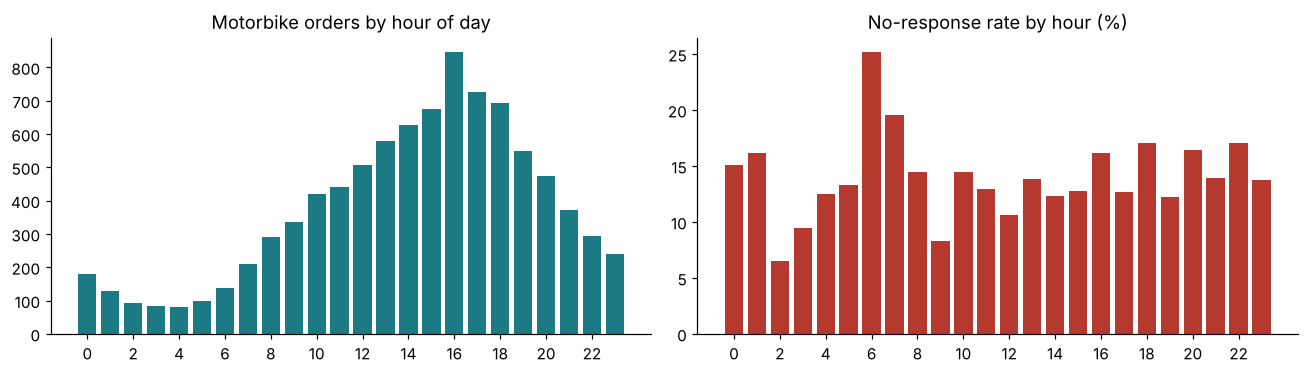

In [16]:
hr = m.groupby(m['dt'].dt.hour).agg(orders=('nr', 'size'), no_response=('nr', 'mean'))
hr['no_response'] *= 100
print(f"Share of orders 12:00-17:59: {hr.loc[12:17, 'orders'].sum() / hr['orders'].sum():.1%}")
print(f"Highest no-response hours: {hr['no_response'].nlargest(2).round(1).to_dict()}")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].bar(hr.index, hr['orders'], color=TEAL); ax[0].set(title='Motorbike orders by hour of day', xticks=range(0, 24, 2))
ax[1].bar(hr.index, hr['no_response'], color=RED); ax[1].set(title='No-response rate by hour (%)', xticks=range(0, 24, 2))
plt.tight_layout(); plt.show()

## Slides 13 and 15: unpaid wasted trips and the cost of paying for no-shows

In [17]:
m['next_gap_min'] = (m.groupby('individual_identifier')['dt'].shift(-1) - m['dt']).dt.total_seconds() / 60
near = m[m['next_gap_min'] <= 180]
gap_noshow = near.loc[near['status'] == 'Rider did not show', 'next_gap_min'].median()
gap_cancel = near.loc[near['status'] == 'Rider cancelled', 'next_gap_min'].median()
print(f"Median minutes to the courier's next offer: after a customer no-show {gap_noshow:.0f}, after a customer cancellation {gap_cancel:.0f}")
print(f"Upper-bound loss per no-show: {gap_noshow:.0f} min x KSh {per_hour:.0f}/h = KSh {gap_noshow/60*per_hour:.0f}")

noshows = m[m['status'] == 'Rider did not show']
print(f"Motorbike no-shows May-Aug 2026: {len(noshows)}; paying KSh 100 each = KSh {len(noshows)*100:,}")
midday = noshows[noshows['dt'].dt.hour.between(12, 17)]
midday_fare = m.loc[(m['status'] == FIN) & m['dt'].dt.hour.between(12, 17), 'trip_priceksh'].median()
print(f"Midday (12:00-17:59) no-shows: {len(midday)}; 100% of median midday fare (KSh {midday_fare:.0f}) = KSh {len(midday)*midday_fare:,.0f}")

Median minutes to the courier's next offer: after a customer no-show 17, after a customer cancellation 4
Upper-bound loss per no-show: 17 min x KSh 308/h = KSh 87
Motorbike no-shows May-Aug 2026: 190; paying KSh 100 each = KSh 19,000
Midday (12:00-17:59) no-shows: 78; 100% of median midday fare (KSh 180) = KSh 14,040


## Slide 16: expected impact (estimate)

In [18]:
uplift = counterfactual - (moto['status'] == FIN).mean()
offers_per_day = m.groupby(['individual_identifier', 'day']).size().mean()
mean_fare = fin_fare.mean()
print(f"Completion: {(moto['status']==FIN).mean():.1%} -> {counterfactual:.1%} (+{uplift*100:.1f} pts)")
print(f"Per courier-day: {offers_per_day:.1f} offers x {uplift:.3f} = +{offers_per_day*uplift:.2f} finished orders"
      f" x mean fare KSh {mean_fare:.0f} = +KSh {offers_per_day*uplift*mean_fare:.0f}")
print(f"Over four months: {len(moto):,} orders x {uplift:.3f} = about {len(moto)*uplift:.0f} more finished orders")

Completion: 56.0% -> 61.6% (+5.5 pts)
Per courier-day: 16.2 offers x 0.055 = +0.89 finished orders x mean fare KSh 204 = +KSh 182
Over four months: 9,086 orders x 0.055 = about 502 more finished orders
